# LAB 3 - Bài 5 (Trang 26): Gom cụm MNIST bằng k-Means và so sánh với nhãn lớp
Hồng Kim Dung - 6451071009

## Đọc dữ liệu MNIST và làm phẳng ảnh

In [1]:
print("Hồng Kim Dung - 6451071009")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# k-Means là thuật toán không giám sát: chỉ dùng ảnh, KHÔNG dùng nhãn khi gom cụm
X = train_images.reshape(len(train_images), -1) / 255.0     # (60000, 784), chuẩn hóa [0,1]
y = train_labels                                            # nhãn thật, chỉ dùng để so sánh sau
print("X:", X.shape, "| y:", y.shape)

Hồng Kim Dung - 6451071009
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X: (60000, 784) | y: (60000,)


## Gom cụm bằng k-Means (k = 10, chạy khoảng 1-3 phút)

In [2]:
print("Hồng Kim Dung - 6451071009")
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=10, n_init=3, random_state=42)
cluster_labels = kmeans.fit_predict(X)

print("Số mẫu mỗi cụm:")
print(pd.Series(cluster_labels).value_counts().sort_index())

Hồng Kim Dung - 6451071009
Số mẫu mỗi cụm:
0    4534
1    5834
2    4578
3    8555
4    5855
5    5500
6    7326
7    4517
8    8933
9    4368
Name: count, dtype: int64


## So sánh cụm với nhãn lớp: bảng đối chiếu (heat map)

Hồng Kim Dung - 6451071009
Nhãn thật     0     1     2     3     4     5     6     7     8     9
Cụm                                                                  
0             7     9  4157   173    29     5    53    40    44    17
1             2  3650   381   407   154   149   185   336   315   255
2          4308     0    44    22     7    54    53    20    29    41
3             5    10    68    36  1883   163     3  3774   165  2448
4            79     8   170   956    14  1009    16    15  3516    72
5          1087     6   210   431   211  1568  1693    10   261    23
6           232     6   276  3857     0  1807    34     5  1028    81
7             2  3042   330    49   208   233    39   256   273    85
8            45     6   190   171  3193   372    55  1805   178  2918
9           156     5   132    29   143    61  3787     4    42     9


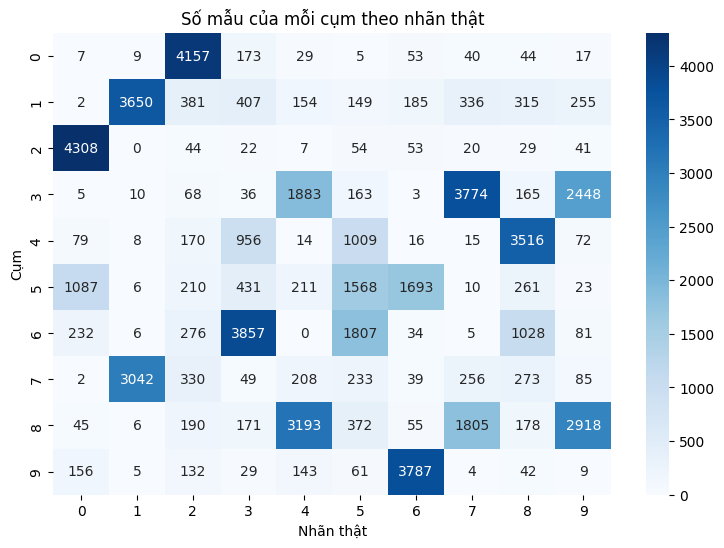

In [3]:
print("Hồng Kim Dung - 6451071009")
bang = pd.crosstab(cluster_labels, y, rownames=["Cụm"], colnames=["Nhãn thật"])
print(bang)

plt.figure(figsize=(9, 6))
sns.heatmap(bang, annot=True, fmt="d", cmap="Blues")
plt.title("Số mẫu của mỗi cụm theo nhãn thật")
plt.show()

## Gán nhãn cho cụm theo nhãn chiếm đa số và tính độ chính xác

In [4]:
print("Hồng Kim Dung - 6451071009")
from sklearn.metrics import accuracy_score, classification_report

# Mỗi cụm được gán nhãn là chữ số xuất hiện nhiều nhất trong cụm đó
cluster_to_digit = {c: bang.loc[c].idxmax() for c in bang.index}
print("Cụm -> chữ số chiếm đa số:", cluster_to_digit)

y_pred = np.array([cluster_to_digit[c] for c in cluster_labels])
print("Accuracy (sau khi gán nhãn theo đa số):", accuracy_score(y, y_pred))

# Độ tinh khiết (purity) của từng cụm
purity = bang.max(axis=1) / bang.sum(axis=1)
print("\nĐộ tinh khiết của từng cụm:")
print(purity.round(4))
print("Purity tổng thể:", bang.max(axis=1).sum() / bang.values.sum())

print(classification_report(y, y_pred, digits=4))

Hồng Kim Dung - 6451071009
Cụm -> chữ số chiếm đa số: {0: np.uint8(2), 1: np.uint8(1), 2: np.uint8(0), 3: np.uint8(7), 4: np.uint8(8), 5: np.uint8(6), 6: np.uint8(3), 7: np.uint8(1), 8: np.uint8(4), 9: np.uint8(6)}
Accuracy (sau khi gán nhãn theo đa số): 0.58295

Độ tinh khiết của từng cụm:
Cụm
0    0.9169
1    0.6256
2    0.9410
3    0.4411
4    0.6005
5    0.3078
6    0.5265
7    0.6735
8    0.3574
9    0.8670
dtype: float64
Purity tổng thể: 0.58295
              precision    recall  f1-score   support

           0     0.9410    0.7273    0.8205      5923
           1     0.6465    0.9926    0.7830      6742
           2     0.9169    0.6977    0.7924      5958
           3     0.5265    0.6291    0.5732      6131
           4     0.3574    0.5466    0.4322      5842
           5     0.0000    0.0000    0.0000      5421
           6     0.5553    0.9260    0.6943      5918
           7     0.4411    0.6024    0.5093      6265
           8     0.6005    0.6009    0.6007      5851
   

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Các độ đo so sánh gom cụm với nhãn thật

In [5]:
print("Hồng Kim Dung - 6451071009")
from sklearn import metrics

print("Adjusted Rand Index (ARI)      :", metrics.adjusted_rand_score(y, cluster_labels))
print("Normalized Mutual Info (NMI)   :", metrics.normalized_mutual_info_score(y, cluster_labels))
print("Homogeneity                    :", metrics.homogeneity_score(y, cluster_labels))
print("Completeness                   :", metrics.completeness_score(y, cluster_labels))
print("V-measure                      :", metrics.v_measure_score(y, cluster_labels))

# Silhouette trên mẫu ngẫu nhiên 10000 ảnh (tính trên toàn bộ 60000 ảnh sẽ rất chậm)
idx = np.random.RandomState(42).choice(len(X), 10000, replace=False)
print("Silhouette (mẫu 10000 ảnh)     :", metrics.silhouette_score(X[idx], cluster_labels[idx]))

Hồng Kim Dung - 6451071009
Adjusted Rand Index (ARI)      : 0.36341787290143635
Normalized Mutual Info (NMI)   : 0.4977741594744755
Homogeneity                    : 0.49416110359486765
Completeness                   : 0.5014404381641628
V-measure                      : 0.49777415947447556
Silhouette (mẫu 10000 ảnh)     : 0.05764013914866018


## Hiển thị tâm cụm dưới dạng ảnh

Hồng Kim Dung - 6451071009


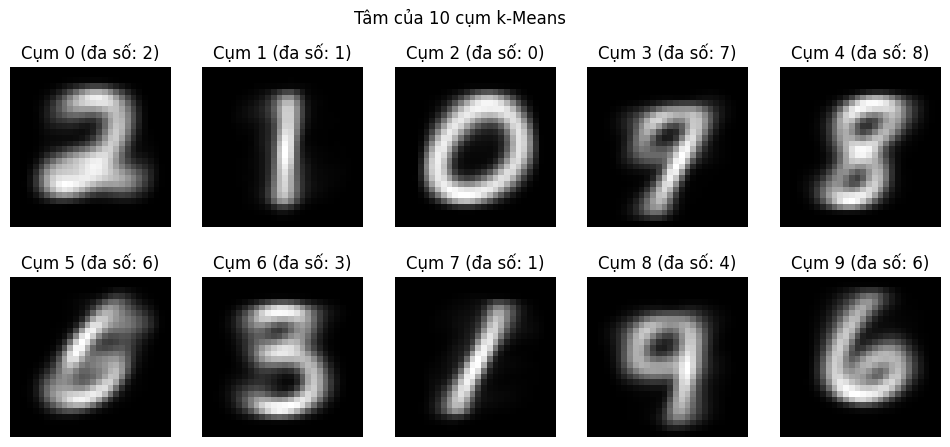

In [6]:
print("Hồng Kim Dung - 6451071009")
plt.figure(figsize=(12, 5))
for c in range(10):
    plt.subplot(2, 5, c + 1)
    plt.imshow(kmeans.cluster_centers_[c].reshape(28, 28), cmap="gray")
    plt.title(f"Cụm {c} (đa số: {cluster_to_digit[c]})")
    plt.axis("off")
plt.suptitle("Tâm của 10 cụm k-Means")
plt.show()